# 공유자전거 대여 수요 예측 — 회귀 미니프로젝트

**모듈 1 · Day 1 · 8교시 / TODO Notebook**

- 데이터: UCI Bike Sharing Dataset의 `hour.csv`
- 예측 대상: 시간당 총 대여량 `cnt`
- 개발 방법: **공통 코드 실행 → TODO 직접 구현 → CP-01~08 결과 확인**
- 이 Notebook은 *미완성 실습 템플릿*입니다. `...` 부분을 완성하기 전에는 일부 셀이 오류를 발생할 수 있습니다.
- 실습 안내 교안과 함께 사용합니다. TODO의 정답이나 모델 성능값은 제공하지 않습니다.
- VS Code에서 `ai-mini-projects/.venv`의 Python 3.11 커널을 선택합니다.
- **작업 폴더**: `mini-project-01/code/` (데이터 상대경로 `../data/hour.csv`)

> **주의**: Test 데이터는 최종 ⑧교시 평가에서만 사용합니다. 모든 코드는 ①부터 순서대로 실행합니다.

---
## ① 데이터 탐색 및 시각화 — CP-01
**목표:** 데이터 구조·품질을 확인하고 시간대별 평균 대여량을 시각화합니다.

### ①-1. 데이터 불러오기 — 공통 코드

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_PATH = "../data/hour.csv"
df = pd.read_csv(DATA_PATH)
print("데이터 로딩 완료")

#한글깨짐방지
plt.rc('font', family='Malgun Gothic')  # 윈도우 (맑은 고딕)

# 마이너스 기호가 폰트에서 깨지는 현상 방지
plt.rcParams['axes.unicode_minus'] = False

데이터 로딩 완료


### ①-2. 데이터 구조 및 품질 확인 — TODO

In [7]:
# TODO 1-1. 데이터의 행·열 개수와 자료형을 확인합니다.
# 힌트: shape, dtypes
print(f"데이터 갯수: {df.shape[0]}개, 컬럼 수: {df.shape[1]}개 \n")



데이터 갯수: 17379개, 컬럼 수: 17개 



In [8]:

# TODO 1-2. 처음 5개 행과 기초 통계량을 확인합니다.
# 힌트: head(), describe()
print("=== 상위 n개 데이터 ===")
display(df.head(5))


=== 상위 n개 데이터 ===


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [11]:
# TODO 1-3. 결측값과 중복 행 개수를 확인합니다.
# 힌트: isna().sum(), duplicated().sum()

missing_count = df.isna().sum().sum()
duplicate_count = df.duplicated().sum()

print(f"전체 결측값 개수: {missing_count:,}개")
print(f"중복 행 개수: {duplicate_count:,}개")

전체 결측값 개수: 0개
중복 행 개수: 0개


In [14]:
# ####################################
# 데이터 파악을 위해 만들어 본거
# ####################################


# 컬럼 한글명
column_names = {
    'instant': '고유 번호',
    'dteday': '날짜',
    'season': '계절',
    'yr': '연도',
    'mnth': '월',
    'hr': '시간',
    'holiday': '공휴일 여부',
    'weekday': '요일',
    'workingday': '근무일 여부',
    'weathersit': '날씨 상태',
    'temp': '기온',
    'atemp': '체감 온도',
    'hum': '습도',
    'windspeed': '풍속',
    'casual': '비회원 대여 수',
    'registered': '회원 대여 수',
    'cnt': '전체 대여 수'
}

# 고유값 표시 설정
MAX_UNIQUE_DISPLAY = 20
SHOW_FIRST = 5


# 데이터프레임 컬럼 분석 함수
def analyze_columns(df, column_names):

    result = []

    for i, col in enumerate(df.columns, 1):

        s = df[col]

        # 기본 정보
        name = column_names.get(col, col)
        dtype = str(s.dtype)
        unique_count = s.nunique()
        missing_count = s.isna().sum()

        # 기본값
        min_value = '-'
        max_value = '-'
        value_info = '-'

        # 숫자형 컬럼: 최소값, 최대값
        if pd.api.types.is_numeric_dtype(s) and not pd.api.types.is_bool_dtype(s):

            if s.notna().any():
                min_value = s.min()
                max_value = s.max()

        # 고유값 추출
        values = s.dropna().unique()

        # 숫자는 숫자 크기순, 문자는 가나다순 등으로 정렬
        values = sorted(values)

        # NumPy 자료형을 일반 Python 자료형으로 변환
        values = [
            v.item() if hasattr(v, 'item') else v
            for v in values
        ]

        # 고유값 표시
        if unique_count <= MAX_UNIQUE_DISPLAY:

            value_info = ', '.join(map(str, values))

        else:

            first_values = values[:SHOW_FIRST]
            last_value = values[-1]

            value_info = (
                ', '.join(map(str, first_values))
                + f', ... , {last_value}'
            )

        # 결과 저장
        result.append({
            '번호': i,
            '컬럼명': col,
            '한글명': name,
            '자료형': dtype,
            '고유값 개수': unique_count,
            '결측치': missing_count,
            '최소값': min_value,
            '최대값': max_value,
            '고유값': value_info
        })

    return pd.DataFrame(result)


# 결과 출력
print(f"전체 데이터: {df.shape[0]:,}행 × {df.shape[1]}열")

display(
    analyze_columns(df, column_names).style.hide(axis='index')
)

전체 데이터: 17,379행 × 17열


번호,컬럼명,한글명,자료형,고유값 개수,결측치,최소값,최대값,고유값
1,instant,고유 번호,int64,17379,0,1,17379,"1, 2, 3, 4, 5, ... , 17379"
2,dteday,날짜,str,731,0,-,-,"2011-01-01, 2011-01-02, 2011-01-03, 2011-01-04, 2011-01-05, ... , 2012-12-31"
3,season,계절,int64,4,0,1,4,"1, 2, 3, 4"
4,yr,연도,int64,2,0,0,1,"0, 1"
5,mnth,월,int64,12,0,1,12,"1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12"
6,hr,시간,int64,24,0,0,23,"0, 1, 2, 3, 4, ... , 23"
7,holiday,공휴일 여부,int64,2,0,0,1,"0, 1"
8,weekday,요일,int64,7,0,0,6,"0, 1, 2, 3, 4, 5, 6"
9,workingday,근무일 여부,int64,2,0,0,1,"0, 1"
10,weathersit,날씨 상태,int64,4,0,1,4,"1, 2, 3, 4"


### ①-3. 대여량 분포 및 시간대별 분석 — TODO

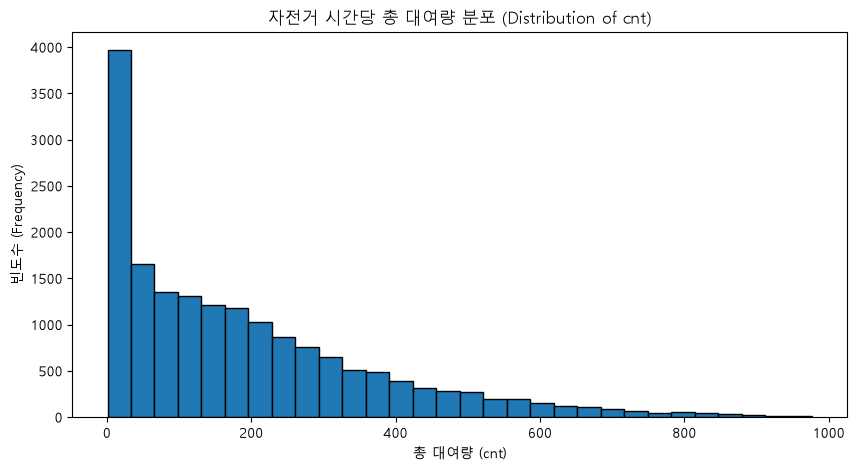

In [16]:
# TODO 1-4. cnt의 분포를 히스토그램으로 시각화합니다.
# 힌트: plt.hist(), plt.xlabel(), plt.ylabel(), plt.show()

plt.figure(figsize=(10, 5))

plt.hist(df['cnt'], bins=30, edgecolor='black')

plt.xlabel('총 대여량 (cnt)')                                           # X축 라벨 (한글)
plt.ylabel('빈도수 (Frequency)')                                            # Y축 라벨 (한글)
plt.title('자전거 시간당 총 대여량 분포 (Distribution of cnt)')   

plt.show()

In [18]:
# TODO 1-5. 시간대(hr)별 평균 대여량을 계산합니다.
# 힌트: groupby("hr")["cnt"].mean()
hourly_mean = df.groupby("hr")["cnt"].mean()

print(hourly_mean)

hr
0      53.898072
1      33.375691
2      22.869930
3      11.727403
4       6.352941
5      19.889819
6      76.044138
7     212.064649
8     359.011004
9     219.309491
10    173.668501
11    208.143054
12    253.315934
13    253.661180
14    240.949246
15    251.233196
16    311.983562
17    461.452055
18    425.510989
19    311.523352
20    226.030220
21    172.314560
22    131.335165
23     87.831044
Name: cnt, dtype: float64


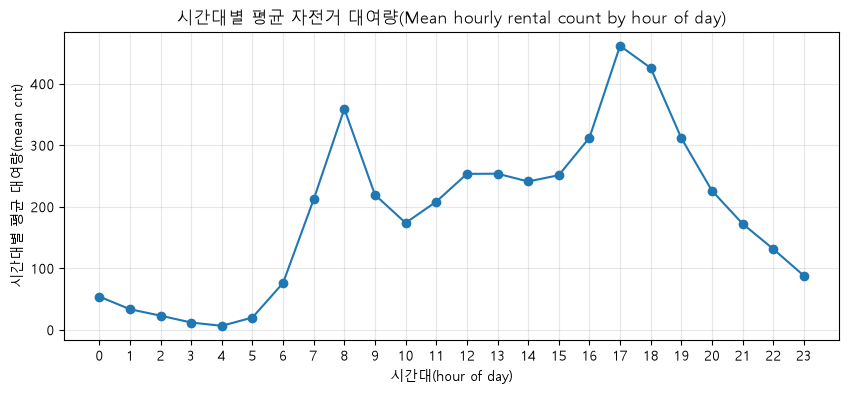

In [22]:
# [공통] 그래프 기본 설정
plt.figure(figsize=(10, 4))

# TODO 1-6. 시간대별 평균 대여량 선 그래프를 그립니다.
# 힌트: plt.plot(hourly_mean.index, hourly_mean.values, marker="o")
plt.plot(
    hourly_mean.index,
    hourly_mean.values,
    marker="o"
)


plt.xticks(range(0, 24))
plt.xlabel("시간대(hour of day)")
plt.ylabel("시간대별 평균 대여량(mean cnt)")
plt.title("시간대별 평균 자전거 대여량(Mean hourly rental count by hour of day)")
plt.grid(alpha=0.3)
plt.show()

**[CP-01] 완료 기준:** 데이터 크기·결측값·중복 여부를 확인하고, `cnt` 분포와 시간대별 평균 대여량 그래프를 완성합니다.

**선택 심화:** 평일과 주말의 시간대별 대여량을 비교해 봅니다.

---
## ② 입력 특성 선택 및 상관관계 분석 — CP-02
**목표:** 날짜별 데이터 분할, 누수 확인, Train 상관관계 분석을 마치고 입력 특성을 결정합니다.

### ②-1. 시간 순서 분할 — 일부 공통 코드 + TODO

In [24]:
# [공통] 날짜 변환 및 시간 순서 정렬

# 문자열 형태의 날짜를 datetime 형식으로 변환
df["dteday"] = pd.to_datetime(df["dteday"])   

# 날짜와 시간(hr)을 기준으로 오름차순 정렬
df = df.sort_values(["dteday", "hr"]).reset_index(drop=True) 

# 중복을 제외한 전체 날짜 목록 추출 및 정렬
dates = np.sort(df["dteday"].unique())

# 전체 날짜 개수 확인
n_dates = len(dates)

# TODO 2-1. 날짜 기준 Train 약 70%, Validation 약 15%, 나머지 Test로 분할합니다.
# 같은 날짜의 행은 반드시 같은 집합에 포함되어야 합니다.
# 힌트: int(), 날짜 배열 슬라이싱, .isin()


# 전체 날짜 중 Train에 사용할 날짜 개수 계산 (70%)
n_train = int(n_dates * 0.70)

# 전체 날짜 중 Validation에 사용할 날짜 개수 계산 (15%)
n_valid = int(n_dates * 0.15)

# 날짜 배열의 앞에서부터 70%를 Train 날짜로 지정
train_dates = dates[:n_train]

# Train 다음 날짜부터 15%를 Validation 날짜로 지정
valid_dates = dates[n_train:n_train + n_valid]

# Validation 다음 날짜부터 마지막까지 Test 날짜로 지정
test_dates = dates[n_train + n_valid:]


# 각 날짜에 해당하는 모든 행을 데이터프레임으로 분리

# Train 날짜에 해당하는 데이터 추출
train_df = df[df["dteday"].isin(train_dates)].copy()

# Validation 날짜에 해당하는 데이터 추출
valid_df = df[df["dteday"].isin(valid_dates)].copy()

# Test 날짜에 해당하는 데이터 추출
test_df = df[df["dteday"].isin(test_dates)].copy()

In [44]:
# [공통] 분할 범위 점검
for name, part in [
    ("Train", train_df),
    ("Validation", valid_df),
    ("Test", test_df),
]:
    print(name, part.shape)
    print(part["dteday"].min(), "~", part["dteday"].max())
    print("cnt 평균:", round(part["cnt"].mean(), 2))

Train (12139, 17)
2011-01-01 00:00:00 ~ 2012-05-25 00:00:00
cnt 평균: 159.72
Validation (2616, 17)
2012-05-26 00:00:00 ~ 2012-09-11 00:00:00
cnt 평균: 281.04
Test (2624, 17)
2012-09-12 00:00:00 ~ 2012-12-31 00:00:00
cnt 평균: 235.76


### ②-2. 데이터 누수 확인 — TODO

In [29]:
# TODO 2-2. casual + registered == cnt가 모든 행에서 성립하는지 확인합니다.
# 힌트: 비교식과 .all()
same = (df["casual"] + df["registered"] == df["cnt"]).all()
print("데이터 관계 확인:", same)


데이터 관계 확인: True


In [35]:

# TODO (추가 확인). casual, registered, cnt의 상관관계를 비교해 봅니다.

# 세 컬럼 간 상관계수 계산
corr_matrix = df[['casual', 'registered', 'cnt']].corr()

print("--- 컬럼 간 상관관계 분석 ---")
display(corr_matrix.round(3))

# 총 대여량(cnt) = 회원 대여량(registered) + 비회원 대여량(casual)




--- 컬럼 간 상관관계 분석 ---


,casual,registered,cnt
casual,1.000,0.507,0.695
registered,0.507,1.000,0.972
cnt,0.695,0.972,1.000


### ②-3. 상관관계 분석 — TODO

In [39]:
# [공통] 분석에 사용할 컬럼
corr_cols = ["temp", "atemp", "hum", "windspeed", "cnt"]

# TODO 2-3. Train 데이터로만 상관계수를 계산합니다.
# 힌트: train_df[corr_cols].corr()
# Train 데이터에서 지정한 컬럼만 선택하여 상관계수 계산
corr = train_df[corr_cols].corr()

display(corr.round(3))

,temp,atemp,hum,windspeed,cnt
temp,1.000,0.992,-0.016,-0.015,0.398
atemp,0.992,1.000,-0.000,-0.058,0.398
hum,-0.016,-0.000,1.000,-0.297,-0.301
windspeed,-0.015,-0.058,-0.297,1.000,0.094
cnt,0.398,0.398,-0.301,0.094,1.000


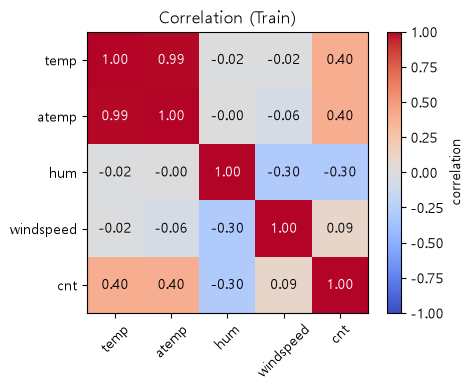

In [41]:
# [공통] 상관관계 시각화 기본 구조
plt.figure(figsize=(5, 4))

# TODO 2-4. 상관관계 행렬을 히트맵으로 시각화합니다.
# 힌트: plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
#       plt.colorbar(label="correlation")

plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="correlation")


# (선택 추천) 히트맵 각 칸에 상관계수 수치를 텍스트로 적어주기
for i in range(len(corr)):
    for j in range(len(corr.columns)):
        value = corr.iloc[i, j]

        plt.text(
            j, i,
            f"{value:.2f}",
            ha="center",
            va="center",
            color="black" if abs(value) < 0.5 else "white"
        )

# 축 이름 표시
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45)
plt.yticks(range(len(corr.index)), corr.index)

plt.title("Correlation (Train)")
plt.tight_layout()
plt.show()

### ②-4. 입력 특성 선택 — TODO (핵심 의사결정 ①)

In [42]:
# TODO 2-5. 모델에 사용할 입력 컬럼을 선택합니다.
# 다음을 검토하세요: 타깃 cnt, 대여 후 집계값, 행 식별자, 유사한 정보를 가진 컬럼.
# 목록과 제외 이유는 안내 교안에 따라 스스로 결정합니다.
FEATURES = [
    # 1. 꼭 넣어야 하는 핵심 피처 (시간/계절/날씨/날짜 정보)
    "season",     # 계절 (1:봄, 2:여름, 3:가을, 4:겨울)
    "yr",         # 연도 (0:2011, 1:2012)
    "mnth",       # 월 (1~12)
    "hr",         # 시간 (0~23)
    "holiday",    # 휴일 여부 (0/1)
    "weekday",    # 요일 (0~6)
    "workingday", # 근무일 여부 (0/1)
    "weathersit", # 날씨 (1~4)
    "temp",       # 온도
    "atemp",      # 체감온도
    "hum",        # 습도
    "windspeed"   # 풍속
]
# 2. 넣으면 안 되는 것 (치명적 누수): cnt(총 대여량), casual(비회원 대여량), registered(회원 대여량)->정답 및 정답의 구성 요소)
# 3. 상관없는거: instant(행 번호), dteday(날짜 문자열->년+월+요일)
TARGET = "cnt"

print("사용할 특성:", FEATURES)

# 12개의 특성을 사용

사용할 특성: ['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed']


In [43]:
# [공통] 입력 X와 정답 y 분리
X_train = train_df[FEATURES].copy()
X_valid = valid_df[FEATURES].copy()
X_test = test_df[FEATURES].copy()

y_train = train_df[TARGET]
y_valid = valid_df[TARGET]
y_test = test_df[TARGET]

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_valid.shape, y_valid.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (12139, 12) (12139,)
Validation: (2616, 12) (2616,)
Test: (2624, 12) (2624,)


**[CP-02] 완료 기준 :** 분할한 데이터의 기간·크기를 확인하고, 누수 검증 결과·Train 상관관계 표·선택한 `FEATURES`를 설명할 수 있습니다.

---
## ③ 특성공학 및 데이터 전처리 — CP-03
**목표:** 출퇴근 시간 특성을 생성하고, 인코딩·표준화·전처리 결합을 구현합니다.

### ③-1. 출퇴근 특성 생성 — TODO

In [45]:
# [공통] 실습에서 사용할 출퇴근 시간 가정
COMMUTE_HOURS = [7, 8, 9, 17, 18, 19]


def add_commute_feature(X):
    """기존 hr와 workingday로 is_commute_hour 특성을 추가합니다."""
    X = X.copy()

    # TODO 3-1. workingday == 1이면서 hr이 COMMUTE_HOURS에 있으면 1, 아니면 0
    # 힌트: isin(), &, astype(int)

    X["is_commute_hour"] = (
        (X["workingday"] == 1) & (X["hr"].isin(COMMUTE_HOURS))
    ).astype(int)
    return X


# [공통] 모든 집합에 같은 특성공학 함수 적용
X_train = add_commute_feature(X_train)
X_valid = add_commute_feature(X_valid)
X_test = add_commute_feature(X_test)

In [46]:
# [공통] 간단 검증 — 기대 결과는 [1, 0, 0, 1]
check = pd.DataFrame({"hr": [8, 8, 14, 18], "workingday": [1, 0, 1, 1]})
print(add_commute_feature(check))

   hr  workingday  is_commute_hour
0   8           1                1
1   8           0                0
2  14           1                0
3  18           1                1


### ③-2. 특성 유형 구분 및 ColumnTransformer — TODO

In [52]:
# TODO 3-2. 선택한 입력 특성을 세 유형으로 구분합니다.
# 범주형(One-Hot 인코딩), 수치형(StandardScaler), 이진형(그대로 사용)
# ②교시 FEATURES와 새로 만든 is_commute_hour가 모두 포함되어야 합니다.

# 23시 다음에 0시를 알려줌
for df in [X_train, X_valid, X_test]:
    df['hr_sin'] = np.sin(2 * np.pi * df['hr'] / 24.0)
    df['hr_cos'] = np.cos(2 * np.pi * df['hr'] / 24.0)


# 1. 범주형 특성 (One-Hot 인코딩 대상): 크기/대소 비교 의미가 없고 '종류'를 나타내는 컬럼
categorical_features = [
    "season",     # 계절 (1:봄, 2:여름, 3:가을, 4:겨울)
    "mnth",       # 월 (1~12월)
    "hr",         # 시간 (0~23시)
    "weekday",    # 요일 (0~6)
    "weathersit"  # 날씨 상태 (1~4)
]

# 2. 수치형 특성 (StandardScaler 정규화 대상): 연속적인 실수 값을 가지며 범위 조정이 필요한 컬럼
numeric_features = [
    "temp",       # 온도
    "atemp",      # 체감온도
    "hum",        # 습도
    "windspeed",   # 풍속
    "hr_sin",     # 시간 주기성 (sin)
    "hr_cos"      # 시간 주기성 (cos)
]

# 3. 이진형 특성 (변환 없이 그대로 사용): 이미 0과 1의 값으로 플래그(깃발) 역할을 하는 컬럼
binary_features = [
    "yr",               # 연도 (0:2011, 1:2012)
    "holiday",          # 휴일 여부 (0/1)
    "workingday",       # 근무일 여부 (0/1)
    "is_commute_hour"   # 방금 만든 출퇴근 시간 여부 (0/1)
]

# [공통] 중복/누락 없는지 확인
all_features = categorical_features + numeric_features + binary_features
assert len(all_features) == len(set(all_features)), "특성 목록이 중복됩니다."
assert set(all_features) == set(X_train.columns), "분류되지 않은 컬럼이 있습니다."

print("범주형:", categorical_features)
print("수치형:", numeric_features)
print("이진형:", binary_features)

범주형: ['season', 'mnth', 'hr', 'weekday', 'weathersit']
수치형: ['temp', 'atemp', 'hum', 'windspeed', 'hr_sin', 'hr_cos']
이진형: ['yr', 'holiday', 'workingday', 'is_commute_hour']


In [55]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer


from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer



def make_preprocessor():
    # TODO 3-3. 다음 세 변환을 ColumnTransformer로 결합합니다.
    # 범주형: OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    # 수치형: StandardScaler()
    # 이진형: "passthrough"
    
    preprocessor = ColumnTransformer(
        transformers=[
            ('cat', OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
            ('num', StandardScaler(), numeric_features),
            ('bin', 'passthrough', binary_features)
        ]
    )
    
    return preprocessor


# [공통] 전처리 객체 생성
preprocessor = make_preprocessor()

### ③-3. 전처리 결과 확인 — 공통 코드

In [56]:
# Train에서만 전처리 기준을 학습합니다.
Xt_train = preprocessor.fit_transform(X_train)
Xt_valid = preprocessor.transform(X_valid)

print("변환 전 Train:", X_train.shape, "→ 변환 후:", Xt_train.shape)
print("변환 전 Valid:", X_valid.shape, "→ 변환 후:", Xt_valid.shape)

변환 전 Train: (12139, 15) → 변환 후: (12139, 61)
변환 전 Valid: (2616, 15) → 변환 후: (2616, 61)


**[CP-03] 완료 기준:** `is_commute_hour`를 생성하고 `make_preprocessor()`가 정상 실행되며, Train/Validation 변환 결과를 출력합니다.

**선택 심화:** 시간대의 주기성을 반영하는 특성을 추가해 봅니다.

---
## ④ 기준 모델 및 선형회귀 — CP-04
**목표:** DummyRegressor·LinearRegression을 학습하고 MAE·RMSE·R² 공통 평가 함수를 구현합니다.

### ④-1. 모델 구성과 학습 — TODO

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression

# TODO 4-1. 전처리 + DummyRegressor(strategy="mean") Pipeline 구현
dummy_model = ...

# TODO 4-2. 전처리 + LinearRegression() Pipeline 구현
linear_model = ...

# [공통] 모델 학습
dummy_model.fit(X_train, y_train)
linear_model.fit(X_train, y_train)
print("학습 완료")

### ④-2. 평가 함수 — TODO / 결과 정리 함수 — 공통

In [ ]:
from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    r2_score,
)


def evaluate_regression(model, X, y):
    """MAE, RMSE, R2 딕셔너리를 반환합니다."""
    # TODO 4-3. model.predict(X)로 예측하고 세 지표를 계산합니다.
    pred = ...
    return {
        "MAE": ...,
        "RMSE": ...,
        "R2": ...,
    }


def summarize(name, model):
    """Train·Validation 평가를 한 행으로 정리합니다 (공통)."""
    tr = evaluate_regression(model, X_train, y_train)
    va = evaluate_regression(model, X_valid, y_valid)
    return {
        "Model": name,
        "Train MAE": tr["MAE"],
        "Train RMSE": tr["RMSE"],
        "Train R2": tr["R2"],
        "Valid MAE": va["MAE"],
        "Valid RMSE": va["RMSE"],
        "Valid R2": va["R2"],
    }

In [ ]:
# [공통] 이후 교시에서 결과를 누적할 리스트
results = []
results.append(summarize("DummyRegressor", dummy_model))
results.append(summarize("LinearRegression", linear_model))

# TODO 4-4. 두 모델의 성능을 DataFrame으로 비교합니다.
# 힌트: pd.DataFrame(results).round(3)
...

**[CP-04] 완료 기준:** 두 모델을 학습하고 공통 평가 함수로 Train·Validation 성능을 표로 비교합니다.

---
## ⑤ Decision Tree 모델 개선 — CP-05
**목표:** `max_depth`를 바꿔 학습·검증 MAE를 비교하고 그래프로 표현합니다.

### ⑤-1. 깊이별 모델 학습 — TODO

In [ ]:
from sklearn.tree import DecisionTreeRegressor

# [공통] 실험 설정 및 저장 구조
depths = [3, 6, 12]
tree_models = {}
tree_results = []

# TODO 5-1~5-3. 각 깊이별 Pipeline 생성·학습·평가 결과 수집
for d in depths:
    # TODO 5-1. 전처리 + DecisionTreeRegressor(max_depth=d, random_state=42)
    model = ...

    # TODO 5-2. 모델 학습
    ...

    # [공통] 학습한 모델 보관
    tree_models[d] = model

    # TODO 5-3. summarize()로 성능 결과 수집
    row = ...
    tree_results.append(row)
    results.append(row)

# [공통] 결과 정리
tree_df = pd.DataFrame(tree_results)
tree_df["max_depth"] = depths
display(tree_df.round(3))

### ⑤-2. 모델 복잡도와 오차 시각화 — TODO

In [ ]:
# [공통] 시각화 기본 설정
plt.figure(figsize=(7, 4))

# TODO 5-4. 깊이별 Train MAE와 Validation MAE를 각각 선 그래프로 표시합니다.
# 힌트: plt.plot(tree_df["max_depth"], tree_df["Train MAE"], ...)
...

plt.xticks(depths)
plt.xlabel("max_depth")
plt.ylabel("MAE")
plt.title("Decision Tree: MAE by max_depth")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**[CP-05]완료 기준:** 깊이 3·6·12의 성능표와 Train·Validation MAE 그래프를 완성합니다.

**선택 심화:** `min_samples_leaf` 설정을 추가로 실험합니다.

---
## ⑥ Random Forest 및 모델 통합 비교 — CP-06
**목표:** Random Forest 두 설정을 실험하고 네 종류 모델의 성능을 하나의 표로 비교합니다.

### ⑥-1. Random Forest 실험 — TODO

In [ ]:
from sklearn.ensemble import RandomForestRegressor

# [공통] 비교할 두 설정
rf_configs = {
    "A": {"n_estimators": 50, "max_depth": 10},
    "B": {"n_estimators": 100, "max_depth": 15},
}
rf_models = {}

# TODO 6-1~6-2. 두 설정의 Random Forest Pipeline 학습 및 성능 수집
for key, params in rf_configs.items():
    # TODO: Pipeline 구성 (RandomForestRegressor(**params, random_state=42, n_jobs=-1))
    model = ...

    # TODO: 모델 학습
    ...

    # [공통] 학습한 모델 보관
    rf_models[key] = model

    # TODO: summarize()로 결과를 results에 추가합니다.
    ...

### ⑥-2. 전체 성능표 비교 — TODO

In [ ]:
# [공통] 지금까지 누적한 모델 결과
results_df = pd.DataFrame(results)

# TODO 6-3. Validation MAE가 낮은 순서로 정렬하고 인덱스를 정리합니다.
results_df = ...

# TODO 6-4. Validation MAE - Train MAE를 계산합니다.
results_df["Gap (Valid-Train MAE)"] = ...

display(results_df.round(3))

**[CP-06]완료 기준:** Dummy·Linear·Decision Tree·Random Forest 결과를 같은 Validation MAE 기준으로 비교합니다.

**선택 심화:** 추가 파라미터 탐색이나 시간 순서 교차검증을 시도합니다.

---
## ⑦ 오류 분석 및 최종 모델 선택 — CP-07
**목표:** 두 후보 모델의 예측 오차를 분석하고, 근거를 기록하여 최종 모델을 결정합니다.

### ⑦-1. 후보 모델과 잔차 — TODO

In [ ]:
# TODO 7-1. results_df를 검토하여 오류 분석할 후보 모델 2개를 선택합니다.
# tree_models, rf_models 또는 앞서 학습한 모델 객체를 활용합니다.
candidates = {
    # "후보 이름": 학습된 모델 객체
}

# [공통] 실제값과 시간대 DataFrame
pred_df = pd.DataFrame({
    "hr": X_valid["hr"].values,
    "actual": y_valid.values,
})

# TODO 7-2. 각 모델의 Validation 예측값과 잔차를 계산합니다.
for name, model in candidates.items():
    pred_df[f"pred_{name}"] = ...
    pred_df[f"resid_{name}"] = ...

display(pred_df.head())

### ⑦-2. 실제값과 예측값 시각화 — TODO

In [ ]:
# [공통] 두 후보 모델을 나란히 비교합니다.
assert len(candidates) == 2, "오류 분석 후보를 2개 선택하세요."
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
lim = pred_df["actual"].max() * 1.05

for ax, name in zip(axes, candidates):
    # TODO 7-3. 실제값(x)·예측값(y) 산점도와 y=x 기준선을 작성합니다.
    # 힌트: ax.scatter(), ax.plot()
    ...

    # [공통] 축 및 제목
    ax.set_xlabel("actual cnt")
    ax.set_ylabel("predicted cnt")
    ax.set_title(name)
    ax.set_xlim(0, lim)
    ax.set_ylim(0, lim)

plt.tight_layout()
plt.show()

### ⑦-3. 시간대별 MAE — TODO

In [ ]:
# [공통] 시간대별 오류 DataFrame
hourly_mae = pd.DataFrame(index=range(24))
hourly_mae.index.name = "hr"

for name in candidates:
    # TODO 7-4. 모델별 절대오차와 시간대별 평균 절대오차를 계산합니다.
    abs_err = ...
    hourly_mae[name] = ...

display(hourly_mae.round(1))

In [ ]:
# TODO 7-5. 후보 모델들의 시간대별 MAE를 막대그래프로 표현합니다.
# 힌트: plt.bar(), hourly_mae
...

### ⑦-4. 최종 모델 선택 — 기록

In [ ]:
# **TODO 7-6:** results_df의 Validation MAE, Train·Validation 성능 차이, 예측 오류 분석 결과를 비교하여 최종 모델과 설정을 선택합니다.
# 선택한 모델과 그 근거는 adr.md의 의사결정 ②에 기록합니다.
# 선택한 모델과 설정은 ⑧교시의 최종 학습에 사용합니다.

**[CP-07] 완료 기준:** 잔차와 시간대별 MAE 분석을 완료하고 최종 모델 선택 이유를 설명합니다.

**선택 심화:** Permutation Importance로 입력 특성의 기여도를 분석합니다 (필수 아님).

In [ ]:
# [선택 심화] 특성 중요도
# TODO (선택): sklearn.inspection.permutation_importance 를 사용해
# Validation 데이터에서 각 입력 특성을 섞었을 때 MAE가 얼마나 변하는지 분석합니다.
# 이 셀을 실행하지 않아도 ⑧교시 진행에 영향이 없습니다.

---
## ⑧ 최종 모델 완성 및 예측 — CP-08
**목표:** 선택한 모델을 재학습하고 Test 평가, 모델 저장·재로딩, 입력 한 건 예측까지 구현합니다.

### ⑧-1. 최종 모델 재학습 — TODO

In [ ]:
import joblib
from pathlib import Path

# [공통] Train과 Validation 데이터 결합
X_trainval = pd.concat([X_train, X_valid])
y_trainval = pd.concat([y_train, y_valid])

# TODO 8-1. ⑦에서 선택한 모델과 하이퍼파라미터로 새 estimator를 생성합니다.
# 예: 앞서 사용한 회귀 모델 클래스와 선택한 설정을 사용합니다.
final_estimator = ...

# [공통] 최종 Pipeline은 전처리를 포함해야 합니다.
final_model = Pipeline([
    ("prep", make_preprocessor()),
    ("model", final_estimator),
])

# TODO 8-2. Train + Validation으로 최종 모델을 재학습합니다.
...

### ⑧-2. Test 평가 — TODO

In [ ]:
# TODO 8-3. Test 데이터에 대해 최종 MAE·RMSE·R2를 평가합니다.
# ④에서 작성한 evaluate_regression()을 재사용합니다.
test_scores = ...
print("최종 Test 성능:", test_scores)

### ⑧-3. 최종 모델 저장과 재로딩 — TODO

In [ ]:
# [공통] 결과 폴더와 저장 경로
RESULTS_DIR = Path("../results")
RESULTS_DIR.mkdir(exist_ok=True)
MODEL_PATH = RESULTS_DIR / "01_final_model.joblib"

# TODO 8-4. 전처리+모델 Pipeline을 joblib으로 저장합니다 (compress=3).
...

# TODO 8-5. 저장된 Pipeline을 다시 불러옵니다.
loaded_model = ...

# TODO 8-6. 저장 전후 예측 결과가 일치하는지 확인합니다.
# 힌트: np.allclose(), X_test.iloc[:100]
same_pred = ...
print("저장 전후 예측 일치:", same_pred)

In [ ]:
# [공통] 실험 결과표 저장
results_df.round(3).to_csv(
    RESULTS_DIR / "01_model_comparison.csv", index=False
)
hourly_mae.round(2).to_csv(
    RESULTS_DIR / "01_hourly_mae_validation.csv"
)
print("결과 파일:", sorted(p.name for p in RESULTS_DIR.iterdir()))

### ⑧-4. 단일 입력 예측 함수 — TODO

In [ ]:
def predict_demand(
    model, season, yr, mnth, hr, holiday,
    weekday, workingday, weathersit, temp, hum, windspeed
):
    """한 시간의 입력 조건으로 예상 대여량(정수)을 반환합니다.

    temp, hum, windspeed는 hour.csv와 같은 정규화 값(0~1)으로 입력합니다.
    """
    # TODO 8-7. 전달받은 값으로 입력 1행 DataFrame을 만듭니다.
    # 학습에 사용한 FEATURES 컬럼을 정확히 사용해야 합니다.
    row = ...

    # TODO 8-8. ③에서 만든 동일한 특성공학 함수를 적용합니다.
    row = ...

    # TODO 8-9. 예측값 하나를 구해 정수로 반환합니다.
    pred = ...
    return ...


# [공통] 섭씨 온도를 원본 데이터의 정규화 기온으로 변환
def celsius_to_temp(c):
    return (c + 8) / 47


# [공통] 예측 입력 예제
sample = {
    "season": 4,
    "yr": 1,
    "mnth": 10,
    "hr": 18,
    "holiday": 0,
    "weekday": 3,
    "workingday": 1,
    "weathersit": 1,
    "temp": celsius_to_temp(20),
    "hum": 0.50,
    "windspeed": 0.15,
}

# TODO 8-10. 저장한 모델과 sample을 사용해 predict_demand()를 호출합니다.
# 힌트: predict_demand(loaded_model, **sample)
result = ...
print("예상 대여량:", result)

**[CP-08] 완료 기준 :** 최종 재학습·Test 평가·모델 저장·재로딩·예측 함수가 정상 동작하면 프로젝트 코드가 완성됩니다.